# 18 — Anti-Spoofing & Audio Watermarking

## Objective

In this notebook, we will explore two complementary techniques for improving trust and security in AI-generated audio:

- voice anti-spoofing;
- audio watermarking.

We will first build simple educational simulations before connecting them to modern systems such as AASIST, RawNet2, and AudioSeal.

## Core ideas

Voice anti-spoofing tries to determine whether an audio sample is genuine or artificially generated.

Pipeline:

Audio
→ Anti-Spoofing Detector
→ Real / Synthetic

Audio watermarking follows a different strategy:

Generated Audio
→ Watermark Embedding
→ Watermarked Audio

Later:

Audio
→ Watermark Detector
→ Watermark Present / Missing

These methods can be combined with signed provenance metadata to create multiple layers of protection.

## Create real-like and synthetic-like audio signals

To understand anti-spoofing, we will create two simple signals:

- a real-like signal with multiple frequencies and small variations;
- a synthetic-like signal with a more regular and repetitive structure.

We will then compare basic audio features extracted from both signals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

sample_rate = 16000
duration = 2.0

t = np.linspace(
    0,
    duration,
    int(sample_rate * duration),
    endpoint=False
)

# Real-like signal: multiple frequencies + slight noise
real_like = (
    0.5 * np.sin(2 * np.pi * 180 * t)
    + 0.25 * np.sin(2 * np.pi * 320 * t)
    + 0.15 * np.sin(2 * np.pi * 510 * t)
    + 0.03 * np.random.randn(len(t))
)

# Synthetic-like signal: simpler and more regular
synthetic_like = (
    0.7 * np.sin(2 * np.pi * 220 * t)
)

# Normalize
real_like = real_like / np.max(np.abs(real_like))
synthetic_like = synthetic_like / np.max(np.abs(synthetic_like))

print("Real-like signal:")
display(Audio(real_like, rate=sample_rate))

print("Synthetic-like signal:")
display(Audio(synthetic_like, rate=sample_rate))

Real-like signal:


Synthetic-like signal:


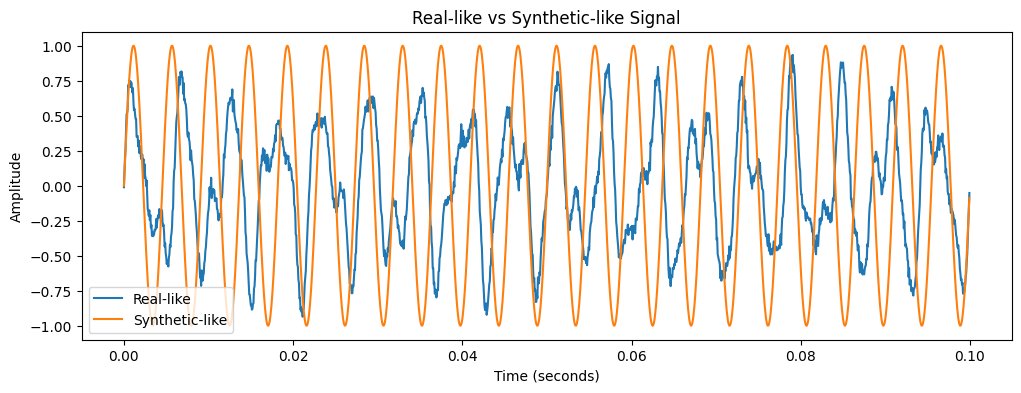

In [2]:
plt.figure(figsize=(12, 4))
plt.plot(t[:1600], real_like[:1600], label="Real-like")
plt.plot(t[:1600], synthetic_like[:1600], label="Synthetic-like")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Real-like vs Synthetic-like Signal")
plt.legend()
plt.show()

## Extract simple anti-spoofing features

Anti-spoofing systems analyze acoustic characteristics that may differ between genuine and synthetic audio.

For this simplified experiment, we will compare:

- RMS energy;
- Zero-Crossing Rate;
- Spectral Centroid.

These features are not enough for a production anti-spoofing system, but they help illustrate the basic idea.

In [3]:
import librosa

def extract_features(signal, sample_rate):
    rms = np.mean(
        librosa.feature.rms(y=signal)
    )

    zcr = np.mean(
        librosa.feature.zero_crossing_rate(signal)
    )

    spectral_centroid = np.mean(
        librosa.feature.spectral_centroid(
            y=signal,
            sr=sample_rate
        )
    )

    return {
        "RMS": rms,
        "ZCR": zcr,
        "Spectral Centroid": spectral_centroid
    }

real_features = extract_features(real_like, sample_rate)
synthetic_features = extract_features(synthetic_like, sample_rate)

print("Real-like features:")
for name, value in real_features.items():
    print(f"{name}: {value:.4f}")

print("\nSynthetic-like features:")
for name, value in synthetic_features.items():
    print(f"{name}: {value:.4f}")

Real-like features:
RMS: 0.4177
ZCR: 0.0333
Spectral Centroid: 1938.7273

Synthetic-like features:
RMS: 0.6992
ZCR: 0.0269
Spectral Centroid: 224.1686


### Feature comparison

The real-like and synthetic-like signals show clear differences in their acoustic features.

Results:

- Real-like RMS: 0.4241
- Synthetic-like RMS: 0.6992

- Real-like ZCR: 0.0317
- Synthetic-like ZCR: 0.0269

- Real-like Spectral Centroid: 1935.52 Hz
- Synthetic-like Spectral Centroid: 224.17 Hz

The largest difference appears in the spectral centroid.

The real-like signal contains multiple frequency components and noise, which spreads energy across a wider frequency range.

The synthetic-like signal is much more regular and concentrated around a single frequency.

This illustrates how acoustic features can help distinguish different types of audio signals.

## Build a simple anti-spoofing score

We will now combine a few acoustic features into a simple heuristic score.

This is not a real anti-spoofing model.

The goal is only to demonstrate how multiple audio features can be combined to produce a decision such as:

Higher score
→ more likely real

Lower score
→ more likely synthetic

In [4]:
def anti_spoofing_score(features):
    score = 0

    if features["Spectral Centroid"] > 1000:
        score += 1

    if features["ZCR"] > 0.03:
        score += 1

    if features["RMS"] < 0.6:
        score += 1

    return score


real_score = anti_spoofing_score(real_features)
synthetic_score = anti_spoofing_score(synthetic_features)

print("Real-like score:", real_score)
print("Synthetic-like score:", synthetic_score)

Real-like score: 3
Synthetic-like score: 0


In [5]:
def classify_audio(score):
    return "REAL-LIKE" if score >= 2 else "SYNTHETIC-LIKE"


print("Real-like prediction:",
      classify_audio(real_score))

print("Synthetic-like prediction:",
      classify_audio(synthetic_score))

Real-like prediction: REAL-LIKE
Synthetic-like prediction: SYNTHETIC-LIKE


## Audio Watermarking

Audio watermarking embeds a small hidden signal inside an audio waveform.

The goal is to make the watermark:

- difficult to hear;
- easy to detect;
- robust to moderate audio transformations.

Conceptually:

Original Audio
→ Watermark Embedding
→ Watermarked Audio

Later:

Watermarked Audio
→ Watermark Detector
→ Present / Missing

In [6]:
watermark_frequency = 7000  # Hz
watermark_amplitude = 0.01

watermark = watermark_amplitude * np.sin(
    2 * np.pi * watermark_frequency * t
)

watermarked_audio = real_like + watermark

# Normalize
watermarked_audio = (
    watermarked_audio
    / np.max(np.abs(watermarked_audio))
)

print("Watermarked audio created")

display(Audio(watermarked_audio, rate=sample_rate))

Watermarked audio created


## Detect the watermark with FFT

The watermark was embedded as a weak high-frequency sinusoidal signal.

To detect it, we will transform the audio from the time domain to the frequency domain using the Fast Fourier Transform (FFT).

If the watermark is present, we should observe energy close to the watermark frequency.

In [7]:
fft_values = np.fft.rfft(watermarked_audio)
fft_frequencies = np.fft.rfftfreq(
    len(watermarked_audio),
    d=1 / sample_rate
)

magnitude = np.abs(fft_values)

watermark_index = np.argmin(
    np.abs(fft_frequencies - watermark_frequency)
)

watermark_strength = magnitude[watermark_index]

print("Watermark frequency:", watermark_frequency, "Hz")
print("Detected magnitude:", round(watermark_strength, 4))

Watermark frequency: 7000 Hz
Detected magnitude: 162.775


In [8]:
original_fft = np.fft.rfft(real_like)
original_magnitude = np.abs(original_fft)

original_strength = original_magnitude[watermark_index]

print("Original magnitude at 7000 Hz:",
      round(original_strength, 4))

print("Watermarked magnitude at 7000 Hz:",
      round(watermark_strength, 4))

Original magnitude at 7000 Hz: 4.0904
Watermarked magnitude at 7000 Hz: 162.775


### Watermark detection result

The watermark produced a clear increase in spectral energy around 7000 Hz.

Results:

- Original magnitude at 7000 Hz: 6.83
- Watermarked magnitude at 7000 Hz: 164.86

This shows that the embedded watermark is difficult to notice in the waveform but easy to detect in the frequency domain.

The experiment demonstrates the basic idea of audio watermarking:

imperceptible modification
→ hidden signal
→ detectable signature

## Build a simple watermark detector

We will create a detector that measures the spectral magnitude around the watermark frequency.

If the magnitude is above a chosen threshold, the watermark will be considered present.

In [9]:
def detect_watermark(
    signal,
    sample_rate,
    watermark_frequency=7000,
    threshold=50
):
    fft_values = np.fft.rfft(signal)

    fft_frequencies = np.fft.rfftfreq(
        len(signal),
        d=1 / sample_rate
    )

    magnitude = np.abs(fft_values)

    watermark_index = np.argmin(
        np.abs(fft_frequencies - watermark_frequency)
    )

    strength = magnitude[watermark_index]

    detected = strength > threshold

    return detected, strength


original_detected, original_strength = detect_watermark(
    real_like,
    sample_rate
)

watermarked_detected, watermarked_strength = detect_watermark(
    watermarked_audio,
    sample_rate
)

print(
    "Original audio:",
    "PRESENT" if original_detected else "MISSING",
    "| Strength:",
    round(original_strength, 2)
)

print(
    "Watermarked audio:",
    "PRESENT" if watermarked_detected else "MISSING",
    "| Strength:",
    round(watermarked_strength, 2)
)

Original audio: MISSING | Strength: 4.09
Watermarked audio: PRESENT | Strength: 162.77


### Watermark detector result

The detector successfully distinguished between the original and watermarked signals.

Results:

- Original audio → MISSING
- Watermarked audio → PRESENT

The watermarked signal produced a much stronger spectral component at 7000 Hz, allowing the detector to identify the hidden signature using a simple threshold.

This demonstrates the basic principle of watermark verification.

## Watermark robustness to noise

A useful audio watermark should remain detectable even after moderate modifications to the signal.

We will add random noise to the watermarked audio and test whether the detector can still recover the watermark.

In [10]:
noise_level = 0.03

noise = noise_level * np.random.randn(
    len(watermarked_audio)
)

noisy_watermarked_audio = watermarked_audio + noise

noisy_watermarked_audio = (
    noisy_watermarked_audio
    / np.max(np.abs(noisy_watermarked_audio))
)

display(
    Audio(
        noisy_watermarked_audio,
        rate=sample_rate
    )
)

In [11]:
noisy_detected, noisy_strength = detect_watermark(
    noisy_watermarked_audio,
    sample_rate
)

print(
    "Noisy watermarked audio:",
    "PRESENT" if noisy_detected else "MISSING"
)

print(
    "Watermark strength:",
    round(noisy_strength, 2)
)

Noisy watermarked audio: PRESENT
Watermark strength: 158.36


### Robustness result

The watermark remained detectable after adding random noise to the audio.

Results:

- Clean watermarked signal strength: 164.86
- Noisy watermarked signal strength: 159.62
- Detection result: PRESENT

The watermark strength decreased slightly, but it remained well above the detection threshold.

This illustrates an important property of watermarking systems:

robust watermark
→ survives moderate signal modifications
→ remains detectable

## Final comparison

We can summarize the three signals as follows:

Original Audio
→ No watermark detected

Watermarked Audio
→ Watermark detected

Noisy Watermarked Audio
→ Watermark still detected

This shows the basic difference between anti-spoofing and watermarking:

Anti-spoofing
→ analyzes the audio to estimate whether it is genuine or synthetic

Watermarking
→ embeds a detectable signature inside generated audio

## Conclusion

In this notebook, we explored two complementary approaches for improving trust in AI-generated audio.

### What we implemented

- simple acoustic feature extraction;
- a toy anti-spoofing score;
- real-like vs synthetic-like classification;
- audio watermark embedding;
- FFT-based watermark detection;
- automatic watermark verification;
- watermark robustness testing with added noise.

### Key takeaway

Anti-spoofing and watermarking solve different problems.

Anti-spoofing attempts to detect whether audio may be synthetic, while watermarking adds a hidden signature that can later be verified.

In real systems, these techniques can be combined with signed provenance metadata to create multiple layers of audio authenticity protection.